In [10]:
from typing import TypedDict
from dotenv import load_dotenv
from rich.console import Console
from rich.pretty import pprint

import getpass, os
from IPython.display import Image, display
from langchain.chat_models import init_chat_model
from langgraph.graph import END, START, StateGraph
from langgraph.store.memory import InMemoryStore

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.base import BaseStore

In [3]:
load_dotenv()

console = Console()


class State(TypedDict):
    """State schema for the context selection workflow.
    
    Attributes:
        topic: The topic for joke generation
        joke: The generated joke content
    """
    topic: str
    joke: str

In [4]:
def _set_env(var : str) -> None:
    """
    Set environment variable if not alread set.
    """
    if not os.environ.get(var):
        raise EnvironmentError(f"{var} not found.!!")


_set_env("GOOGLE_API_KEY")

llm = init_chat_model(
    "gemini-3.5-flash",
    model_provider = "google_genai",
    timeout        = 60,
    max_retries    = 5,
    temperature    = 0,
)

In [5]:
def generate_joke(state: State) -> dict[str, str]:
    """Generate an initial joke about the topic.
    
    Args:
        state: Current state containing the topic
        
    Returns:
        Dictionary with the generated joke
    """
    msg = llm.invoke(f"Write a short joke about {state['topic']}")
    return {"joke": msg.content}


def improve_joke(state: State) -> dict[str, str]:
    """Improve an existing joke by adding wordplay.
    
    This demonstrates selecting context from state - we read the existing
    joke from state and use it to generate an improved version.
    
    Args:
        state: Current state containing the original joke
        
    Returns:
        Dictionary with the improved joke
    """
    print(f"Initial joke: {state['joke']}")
    
    msg = llm.invoke(f"Make this joke funnier by adding wordplay: {state['joke']}")
    return {"improved_joke": msg.content}

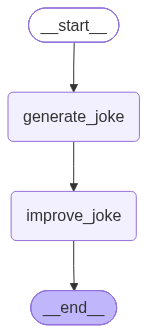

In [6]:
workflow = StateGraph(State)

workflow.add_node("generate_joke", generate_joke)
workflow.add_node("improve_joke",   improve_joke)

workflow.add_edge(START, "generate_joke")
workflow.add_edge("generate_joke", "improve_joke")
workflow.add_edge("improve_joke", END)

chain = workflow.compile()

display(Image(chain.get_graph().draw_mermaid_png()))

In [7]:
joke_generator_state = chain.invoke({"topic" : "Elephant"})

console.print("\n[bold red]Final Workflow State:[/bold red]")
pprint(joke_generator_state)

Initial joke: [{'type': 'text', 'text': "What do you call an elephant that doesn't matter?\n\nAn **irrelephant**!", 'extras': {'signature': 'EtsOCtgOAWkUfRNq2qbcUj7QuW55AEwuOB27bXrNrwU/Wk1h5l8esoZG9ujw7bKTomh0iwdEqaEGZR+/Kw7CXV0L2OljGVZdLJEMAm/AavTTQkgiMDINeiEffnKmiV8yA3s5pg51JFX7m7BYA+C/Y/DJRbpPfnW+1gFpGf5eEwyh4GLBgVYVr2MeIavnJ9u89FR5zYBBtQ38l54gs7IQqirMEEZpcvtwBJQgH2ThNKk0WwPo2RQw3xiutKG2R+N06Obvsu+bja6mRIpk1rKMVCRj9j/3fbX2c3+Ec5Pn3dx+J7vbuDweFMoY05NFsDfcBapcO3fq++LM7Qbi93AsYcWWfG1xPPPaYk00BiCET94WTcAmB9w9yvu1c6q3iKmc3cdLyJC3kPdL9ZP8jH4VTms5mak//tsyEZKE0i99u4L6ueZooZvFFFFWqtqoPdbrWG0PctInWBneHh1eGeUhNUk1kz8h4qH5vvFiN3JgbuE3hOSd5R+x73OXM2Q59b4sNTW/V/EoJxZJsQrl6U2bikS5qvPXKbjjXnWMsEvGA1lAKFihpJGsF4hCf1DwuyDYdrZR0cwyIl7jS0aubIL4GXU2CcQnUCuirGPnr7LZVPxxLiBgYcd/D1chvSSDWN3pGsOwkp7XvRm0r6XWMkqON8AXiiBHU6SYCaO2Nzq/p95sHnNWjjzE8Agd8ZJVCPvL2SwXbJoxCAm9otjrHh8T25NBm1aHptoqz1VzLkRugytL0HByRtz6kp0iR5QGytkl/e48Z9iIdrQrEmiSGPwZYLpJkBmk8T7m4V395BBTcc7K/qFqNsnvhrDXFMHnKBOQNTcBG7WDrhWVrgW0hE84cd67swe

Final Workflow State:

{
│   'topic': 'Elephant',
│   'joke': [
│   │   {
│   │   │   'type': 'text',
│   │   │   'text': "What do you call an elephant that doesn't matter?\n\nAn **irrelephant**!",
│   │   │   'extras': {
│   │   │   │   'signature': 'EtsOCtgOAWkUfRNq2qbcUj7QuW55AEwuOB27bXrNrwU/Wk1h5l8esoZG9ujw7bKTomh0iwdEqaEGZR+/Kw7CXV0L2OljGVZdLJEMAm/AavTTQkgiMDINeiEffnKmiV8yA3s5pg51JFX7m7BYA+C/Y/DJRbpPfnW+1gFpGf5eEwyh4GLBgVYVr2MeIavnJ9u89FR5zYBBtQ38l54gs7IQqirMEEZpcvtwBJQgH2ThNKk0WwPo2RQw3xiutKG2R+N06Obvsu+bja6mRIpk1rKMVCRj9j/3fbX2c3+Ec5Pn3dx+J7vbuDweFMoY05NFsDfcBapcO3fq++LM7Qbi93AsYcWWfG1xPPPaYk00BiCET94WTcAmB9w9yvu1c6q3iKmc3cdLyJC3kPdL9ZP8jH4VTms5mak//tsyEZKE0i99u4L6ueZooZvFFFFWqtqoPdbrWG0PctInWBneHh1eGeUhNUk1kz8h4qH5vvFiN3JgbuE3hOSd5R+x73OXM2Q59b4sNTW/V/EoJxZJsQrl6U2bikS5qvPXKbjjXnWMsEvGA1lAKFihpJGsF4hCf1DwuyDYdrZR0cwyIl7jS0aubIL4GXU2CcQnUCuirGPnr7LZVPxxLiBgYcd/D1chvSSDWN3pGsOwkp7XvRm0r6XWMkqON8AXiiBHU6SYCaO2Nzq/p95sHnNWjjzE8Agd8ZJVCPvL2SwXbJoxCAm9otjrHh8T25NBm1aHptoqz1VzLkRugytL0HByRtz6kp0iR5QGytkl/e48Z9iIdrQrEmiSGPwZYLpJkBmk8T7m4V395BBTcc7K/qFqNsnvhrDXFMHnKBOQNTcBG7WDrhWVrgW0hE84cd67sweKAooF3lJ1dJ2ZZsmHClQKuVP1ipWMlgyVNENVL4iVtrIvpMJwytF1jWdrkGeUzoYV4HacmD8bCJ3vTaxwP+EzLLhfvDLYTGNDSWL44dMtKowIxPWye+JxTeyJuahECiompqAK4bW7IwKmc6Faw9TpxUhQaYMrB2hAZjNn8w8rcUGq6a8N3XoS57L71fSXd6OjL71pOn+PmpKWg7nep/OBbCy/7ETHjeoRzhoZ6Olk3B1taC0RYmnwwovdwVqxF7bal9BrJ/uH3oqNdQ4hkyXUFIYWN+QbOBgxnaWkZMWZxVJPZBUZeCcADOJQvM5PDiK42KyyahwrtfiQ8YihMjHDZop11rjCKihhrmAxgHvNE0v93XCraXi8uNbUyxtrC3pqz3e+K4hvzbtV7y6L4ukrIZSjHMd7OskO3es5ncg+2/4PcrNd9DUT61wxuviASG69HmLGj/ZbOusQzWZjpOAep9IKRUmtOmsV9x9ywiMvosB21nX03LezOWUPMDsHeoktVoPBZAamJlum3qQLfSQNQiO0zlINljKDigInGbqsyzPKGioibPX0M658laY0agp7TOX7XtJJ8+VOnoV6Hr+yeHX3xlHYuf1gp9XJccgmsae885slQp5qwAFRdu8jGiuu3b/wdgGIYgBmPMuVylCxNQNHcoe25J74Xk44wLzT6IW8avmKquxNov1mPtPcspNf19s4mcOAp1Q+OrNFJJ7AHSK+i+kEBj3xzMtWQkndqeOVihUfcIfsPduHPMdSaKa4NxXcnktlokYW4r/88vuMhxMYPbYOddy69ySTrkELTKwDLnmXtrydEdmGVxwglSYl6D9MqKY2dwUJNtLWD9bw1/2W1lt0YWVbOJdp4dv0GwdqQgBVBkUE9mwNkAh9TfCua+8hb1rh17vHH5K1sqKDMB1S+is5EfEV3pAh0HqszBj+8rCKjgWnghAQQtuhrNVqqy9eCqXEYZW8Kb5KJy4/8wptDfYTyPhb6IcukIs16cJAMEM8dC4w3g3/XVrrCRXHCwuBCqFV5TxGkho5NSenPqdQSPOwixGUJZvrDH2QXQss+z+JUnWAwjnc8VH1WTboWIrLwm6B2HeOCXK9BQfAoWFcvwgfsdLDSHAxw/SW7f8pRJBHmhvR1FauFRB6Mzrir9OTyUo9P8FJC8JS26qvCu/Zt3oTBRIZpRXuBkewx7JO6QIxtDw3k0ajxD1JMKr1aLeAwyD212uo9c/V29Rfc0aZkJk3WKRELb1ZiM7uFUKl6GzD2x4bMgO5a3P0RPwiUMxdDz1wiDgvgEzufi7igCaprTtTPQkboWKTqk5DsO8NYSLqTi5HD5acipPhiycx9IayrG2Bi5z63ATUVLj+B22bJdgGuKvlGuk47azAyNtKMlFdOwJ5OGz3jmSWZ19pItrelq7psG8G+gk2wYjarzrZfnkQIK6QnbDLVzEXrPToRAGHKaHuRL8WxnOFFEWO52oFPjlCEnk9oTm3UnKQOrYNa/AdrFeds9zevLho27vfFb7OCGfmyOj9esY0Z2e9ahu6GHK1eP+/iuYzF/YvSXw7/XHGjXh+qjajYfqk8ZqDHpVQ4DENRFM46nqylUjwbPn6GamQveJobG40uKJWMtHCT1iNnn5Z/J6LZLnz5aHHC4p0bvQ32O4='
│   │   │   }
│   │   }
│   ]
}

In [9]:
store = InMemoryStore()

namespace = ("rlm", "joke_generator")

## STORE the generated joke in memory
store.put(
    namespace,
    "last_joke",
    {"joke" : joke_generator_state['joke']}
)

## SELECT the joke from memory
retrieved_joke = store.get(namespace, "last_joke").value

console.print("\n[bold green]Retrieved Context from Memory:[/bold green]")
pprint(retrieved_joke)



Retrieved Context from Memory:

{
│   'joke': [
│   │   {
│   │   │   'type': 'text',
│   │   │   'text': "What do you call an elephant that doesn't matter?\n\nAn **irrelephant**!",
│   │   │   'extras': {
│   │   │   │   'signature': 'EtsOCtgOAWkUfRNq2qbcUj7QuW55AEwuOB27bXrNrwU/Wk1h5l8esoZG9ujw7bKTomh0iwdEqaEGZR+/Kw7CXV0L2OljGVZdLJEMAm/AavTTQkgiMDINeiEffnKmiV8yA3s5pg51JFX7m7BYA+C/Y/DJRbpPfnW+1gFpGf5eEwyh4GLBgVYVr2MeIavnJ9u89FR5zYBBtQ38l54gs7IQqirMEEZpcvtwBJQgH2ThNKk0WwPo2RQw3xiutKG2R+N06Obvsu+bja6mRIpk1rKMVCRj9j/3fbX2c3+Ec5Pn3dx+J7vbuDweFMoY05NFsDfcBapcO3fq++LM7Qbi93AsYcWWfG1xPPPaYk00BiCET94WTcAmB9w9yvu1c6q3iKmc3cdLyJC3kPdL9ZP8jH4VTms5mak//tsyEZKE0i99u4L6ueZooZvFFFFWqtqoPdbrWG0PctInWBneHh1eGeUhNUk1kz8h4qH5vvFiN3JgbuE3hOSd5R+x73OXM2Q59b4sNTW/V/EoJxZJsQrl6U2bikS5qvPXKbjjXnWMsEvGA1lAKFihpJGsF4hCf1DwuyDYdrZR0cwyIl7jS0aubIL4GXU2CcQnUCuirGPnr7LZVPxxLiBgYcd/D1chvSSDWN3pGsOwkp7XvRm0r6XWMkqON8AXiiBHU6SYCaO2Nzq/p95sHnNWjjzE8Agd8ZJVCPvL2SwXbJoxCAm9otjrHh8T25NBm1aHptoqz1VzLkRugytL0HByRtz6kp0iR5QGytkl/e48Z9iIdrQrEmiSGPwZYLpJkBmk8T7m4V395BBTcc7K/qFqNsnvhrDXFMHnKBOQNTcBG7WDrhWVrgW0hE84cd67sweKAooF3lJ1dJ2ZZsmHClQKuVP1ipWMlgyVNENVL4iVtrIvpMJwytF1jWdrkGeUzoYV4HacmD8bCJ3vTaxwP+EzLLhfvDLYTGNDSWL44dMtKowIxPWye+JxTeyJuahECiompqAK4bW7IwKmc6Faw9TpxUhQaYMrB2hAZjNn8w8rcUGq6a8N3XoS57L71fSXd6OjL71pOn+PmpKWg7nep/OBbCy/7ETHjeoRzhoZ6Olk3B1taC0RYmnwwovdwVqxF7bal9BrJ/uH3oqNdQ4hkyXUFIYWN+QbOBgxnaWkZMWZxVJPZBUZeCcADOJQvM5PDiK42KyyahwrtfiQ8YihMjHDZop11rjCKihhrmAxgHvNE0v93XCraXi8uNbUyxtrC3pqz3e+K4hvzbtV7y6L4ukrIZSjHMd7OskO3es5ncg+2/4PcrNd9DUT61wxuviASG69HmLGj/ZbOusQzWZjpOAep9IKRUmtOmsV9x9ywiMvosB21nX03LezOWUPMDsHeoktVoPBZAamJlum3qQLfSQNQiO0zlINljKDigInGbqsyzPKGioibPX0M658laY0agp7TOX7XtJJ8+VOnoV6Hr+yeHX3xlHYuf1gp9XJccgmsae885slQp5qwAFRdu8jGiuu3b/wdgGIYgBmPMuVylCxNQNHcoe25J74Xk44wLzT6IW8avmKquxNov1mPtPcspNf19s4mcOAp1Q+OrNFJJ7AHSK+i+kEBj3xzMtWQkndqeOVihUfcIfsPduHPMdSaKa4NxXcnktlokYW4r/88vuMhxMYPbYOddy69ySTrkELTKwDLnmXtrydEdmGVxwglSYl6D9MqKY2dwUJNtLWD9bw1/2W1lt0YWVbOJdp4dv0GwdqQgBVBkUE9mwNkAh9TfCua+8hb1rh17vHH5K1sqKDMB1S+is5EfEV3pAh0HqszBj+8rCKjgWnghAQQtuhrNVqqy9eCqXEYZW8Kb5KJy4/8wptDfYTyPhb6IcukIs16cJAMEM8dC4w3g3/XVrrCRXHCwuBCqFV5TxGkho5NSenPqdQSPOwixGUJZvrDH2QXQss+z+JUnWAwjnc8VH1WTboWIrLwm6B2HeOCXK9BQfAoWFcvwgfsdLDSHAxw/SW7f8pRJBHmhvR1FauFRB6Mzrir9OTyUo9P8FJC8JS26qvCu/Zt3oTBRIZpRXuBkewx7JO6QIxtDw3k0ajxD1JMKr1aLeAwyD212uo9c/V29Rfc0aZkJk3WKRELb1ZiM7uFUKl6GzD2x4bMgO5a3P0RPwiUMxdDz1wiDgvgEzufi7igCaprTtTPQkboWKTqk5DsO8NYSLqTi5HD5acipPhiycx9IayrG2Bi5z63ATUVLj+B22bJdgGuKvlGuk47azAyNtKMlFdOwJ5OGz3jmSWZ19pItrelq7psG8G+gk2wYjarzrZfnkQIK6QnbDLVzEXrPToRAGHKaHuRL8WxnOFFEWO52oFPjlCEnk9oTm3UnKQOrYNa/AdrFeds9zevLho27vfFb7OCGfmyOj9esY0Z2e9ahu6GHK1eP+/iuYzF/YvSXw7/XHGjXh+qjajYfqk8ZqDHpVQ4DENRFM46nqylUjwbPn6GamQveJobG40uKJWMtHCT1iNnn5Z/J6LZLnz5aHHC4p0bvQ32O4='
│   │   │   }
│   │   }
│   ]
}

In [11]:
## Initialize Storage Components
checkpointer = InMemorySaver()
memory_store = InMemoryStore()

def generate_joke(state: State, store: BaseStore) -> dict[str, str]:
    """Generate a joke with memory-aware context selection.
    
    This function demonstrates selecting context from memory before
    generating new content, ensuring consistency and avoiding duplication.
    
    Args:
        state: Current state containing the topic
        store: Memory store for persistent context
        
    Returns:
        Dictionary with the generated joke
    """
    # Select prior joke from memory if it exists
    prior_joke = store.get(namespace, "last_joke")
    if prior_joke:
        prior_joke_text = prior_joke.value["joke"]
        print(f"Prior joke: {prior_joke_text}")
    else:
        print("Prior joke: None!")

    # Generate a new joke that differs from the prior one
    prompt = (
        f"Write a short joke about {state['topic']}, "
        f"but make it different from any prior joke you've written: {prior_joke_text if prior_joke else 'None'}"
    )
    msg = llm.invoke(prompt)

    # Store the new joke in memory for future context selection
    store.put(namespace, "last_joke", {"joke": msg.content})

    return {"joke": msg.content}

In [12]:
workflow = StateGraph(State)

workflow.add_node("generate_joke", generate_joke)


workflow.add_edge(START, "generate_joke")
workflow.add_edge("generate_joke", END)

chain = workflow.compile(checkpointer=checkpointer, store=memory_store)

In [13]:
config = {"configurable": {"thread_id": "1"}}
joke_generator_state = chain.invoke({"topic": "Elephant"}, config)

Prior joke: None!


In [14]:
latest_state = chain.get_state(config)

console.print("\n[bold magenta]Latest Graph State:[/bold magenta]")
pprint(latest_state)

Latest Graph State:

StateSnapshot(
│   values={
│   │   'topic': 'Elephant',
│   │   'joke': [
│   │   │   {
│   │   │   │   'type': 'text',
│   │   │   │   'text': 'What do you call an elephant that stops drinking coffee?\n\nA **decaf-iderm**!',
│   │   │   │   'extras': {
│   │   │   │   │   'signature': 'ErAkCq0kAWkUfRM6McRmMdOuuLTpTFD+JMVKvBwm4F79GzG4wiKKfCnYWI+Vlk0BSi3RXm6rW8ctR2CaRdD/sYHHtc2l8kqHS4cHyE2TrVn6Eu/L0fHrkjy55JPx8RgKnNGHfnhVwUtTpjCCZoZWHhF6446/eXjzkfpXA6NsOSaF8sEW5hpaUd9DWhSLFugZAEYS93/huL/ZznQokUz+d+uqImNDblK1iXn0GXBEnhaZUhVv2mP4e4S6hq5j1/huwQjEinqXTRWYpLhWG/vrZ+M1yOvzGQib3zT//WRvXWuLSvY7tx7JUg9Ujzo8AE8VX4lny6O8qPOvbJvD6pXiu6+rEcPtSVFIymgcotqTjoHgxJO3uBVcmD2xKiqsGVnoD5jCeYW6PQMOGFVTRj7b90cDnxZsbsxQPImjtaKupJEvOckZb6wMo29HZMPY92L7A3276rFVGChSj5pVDJHjKaRdoXOjmMXfLRjokvt2do1SJNxJZ5xDI0yr9hQYI0iwKljCkDt6zaEHhxo7jP/NGIsiux1V4oQE2V19v4J3EKZEyEBhUnw1+BwpHv/ptKlZQt+IhY7Mig8E+9Sh3S1Fd77PsXhAYDjGeJKUbJ6TEy/eXP6+yYkFtPy1aSWr2YJ93g1p1gOg8xVb6st6qATUirNsbfBn/8NQgF0ep8G90ZSmUIMk1ZS/DRkEMblKoYyRrFjrLjtvpfXxHEdepNSXwvxx4mGsknuaz/bmrHtqSkCfBtGYYv9Sw8oEdszKSZk/PZtzqouo/i8SCANqin3eqtaZR1QZ7NiG/G6CNZRkAXNIsrycOmgIY02/YIeYRSWohW1C4f/AlyNer46YGzf/IWd2HCuHxdanEszCbgfomELL2QHASU6jXdelyC42xQFNHOj8+dex8DYUzH93qpVpBsdtVjAWADw8s/KongwSdPSd0Pt4sLVtxkiRy/Hiu9LFfJgJizNkjBgtntq9yMbN9yO+sDTGlqJjX6WybdChYba2azyN/etEBF8e+03PojNNYap+EwDJHTipMlBUxCk7x9WCUPeKY6LflpLv9UZM9xJOlCubKETvfqES5evF92b6GgAVxcgxC9eNnN5Vo/lJXIux2E2QAUv8Fn9Vi5rfjIeJarfKzOs7YHyc5xKngb/+Y65wdCemUe2yQromumd/wkzvRfjvjS+gc7e6toSR8bIGA9GyVozW//Y0EHKGdok5wD1UK//n30kyaDdx8Oh9vkZNJSRZRJ/aCpNZtyETlySoMDH72ZXGppda2uLPCYm3HkZL3IbEuyaoVsMrJg+FYVQwAtzHpbKgKcwfYxzfV71p9M9UqyR2vPfTbGQxcoWar0I5e5ZyG0X59JIeVBD69AAcWL8/VdcstqCJcMrv5zrLOpaWU9AlDnm2trkMg2wE5aohGuIw+YskJpaGP2G7wkam2Ux7jRkdsW+CordkyBZTdhTGPld/qZHy+A6EAvOFSClHC5GIdOEQkFN98eXh/0TCHaA+9QjWL91rCqAWRCJ8Zky4vziOBh8y0no3k8SbLWwdSnt+xV86jXgsI6htrglDYNi6Nc1PsRQic5KivvqJGb2LXkg3e3GaCuHXGMm2BR2B1MFJmWMlpxdKm+a/oebk4VNLCzHQcFyk7D/01ScpfEGqDKt8vvjPJc2d0neqTQLYQsl/jpKW37fygrIq1jpT37Ho97g1TLqcr2LQp/L4M6Mxhj+Z6nyepCpROAwogTDvwSywEVmpE6OHMJHGWXGLTrGNMoWj2Z7+Tp+kOLCyP9e/ugbz+XT4nimc1MBIDCp/6KdXqaKTG5fgdy4i9xNGVC6MzPbvRLGA4FUdKHaP3EYTP/cSNSbxJd2GqIX1ODd8JozndjwZKfZi3kuiReB7/BkO4si66i8QefjlhcAyRHEv2dHakmAZgDd/eHKEdxecg2hkL16fNpwIz0Yks4y2DY1s6Am3ASpOXRdB+cBQM3AK+1PkBa5h4u7jU2aRwRLQCth3iBLr/vFqhHgIbOlVW6KUtSs43ldAhhOmwlO8Uuz96g3qrEHA0riAR6MfFZcJH2+w9nR1WfqqbOLigucE6Te6K87Q4xAYhrF9WSSp8kOYpFu5QaFhZ8+fCNgqRl/kShTtz68Q3ip+rqjXh6S0pehw2C+pNpS0Y/EEBw9pDqaYfoIgoYiUb430uLApjGEF3+m5mV0O+XWGCZ0bsYyPG2VTbBEHAS+FA4zbZ6HcqsIjmodRWOhttfatgbhwIlepCAg29ByS0DV/RcA2+Kpdmqlkra3B9GK5OZd0Syr3O5VhQsf7c3gyCNf1/d2bHT19bKtnnGuEUmUx/D1SIkvQ+/Jbv77CLCTX4tyPvYgRWiWrRFeCFIs01+o3kj64F1XYPZO7WW4l/Rw9CoegFHRupCAJXwj8awhwnqVI2MtsEvTzjLvuIZbxWUNBWkz5R1aq7qmEYo1Okx1zmL6aeZ/C/sUF9+73Fm9lZVXSQwlC+hpeNLQhOzpmirXS4TdnNYRlifUEBwBCJusFOpJbSp4tuSRuQbHv1Y68p0PlMpqCmytOWJy/tC2pmk1dfl+sY+SrGnPNkcOdysqCIzTABTSUZeY9Z/4NcGH5lrBKPpBSXWSFWV6cCB4TUc7IG1bBfFzmhSA0v8A/4THk8GUDOYg1u4dA+G/v90Cv5iDTGFqIuMwvG6bKzddKFaPuLZ30THo367dm3wGeRKweXDeJDTq0LT6Oml9S3AO5mAWylRn4YbdMyDQQMGhG2ALIY9Hu12P+Ma+nHJK2XoJJHZi1wivATTyYIDRYvk1I+jSzrA3ffWztfjiuj5adOodk4m6EFdmwKrq4COvAaciPyO5xXSdhSdUlhraKwErLHQ4mPNyB6pw6eEPg18y5LOG6hw5h1oi/GbTQDbUW9g6xrEWVUYfFRDfHlIL9eD7Mdod08+fwK6l3IhQOToPsGWxpB7bEfqXEvQOaaUKgjr5cvuY/NGp4TEMIqkwZAl9o6yaMKdVJUqwiJQNPSO8VgL+mFS2GNYoWVxwhG3LH/DF3BndOJvvOC31hQF4SlIPb1HIweu1mA6SIR+3feby7XWirQh0Pqv3eBB1fW2p7Tv9/xN6A+g1NnRHxLEu2zSA3oFVNSV81BRxMs1cSliLVvpG8QwVcKkqWknI77BbvKvj0b8KbBrbkzIx8K8P4B3P6LCMp9NMg7QeUo/i/LZygdS0bgpheIjAMwFYsX/KRI+9bX9hrbJY+jwpYrVe0GEoneY4pAb8JNIuN69j8UfmgdcI7id3LJakWcIiL8iuPYGqpyf3iDi6dA09ccfR7hpfteqngporhAFD9camkVQRuusFbhqgi+1yVtp3IxWiHp2qD1zLfbFS9nrI9/PrQwSddEVcW06OfuqTLwc4AWbk2bIgX1z1B91zPwiOxs0oaZY8beuIRUJc29v8dXI6lY78fRRBw2Y8rpCqM5riLDE8G6u7yJoE48zEL9bXkxsJs1WwXKOlM1aaDr9RWK5LlHUMC1TRLXmYSpqd0X2slboELVjfuky8UsAmgmnzUtW90E8wCthMJkR/GRY6fxRoZH1v5fDIhZZTsn2PMR9Rysv87a4synTqteMoKt29IPewpHyChSpNwf+jCtebeAJti92M05BnsxZ9CM0v6jUelDRYCa+RNwFU8LQ6MoUt0NTqi++5F7bHmAjnQSt4+ezb4/2Ft8VM5Tut+v9g0WlIpWZRY/ngLT3X

In [15]:
config = {"configurable": {"thread_id": "2"}}
joke_generator_state = chain.invoke({"topic": "Elephant"}, config)

Prior joke: [{'type': 'text', 'text': 'What do you call an elephant that stops drinking coffee?\n\nA **decaf-iderm**!', 'extras': {'signature': 'ErAkCq0kAWkUfRM6McRmMdOuuLTpTFD+JMVKvBwm4F79GzG4wiKKfCnYWI+Vlk0BSi3RXm6rW8ctR2CaRdD/sYHHtc2l8kqHS4cHyE2TrVn6Eu/L0fHrkjy55JPx8RgKnNGHfnhVwUtTpjCCZoZWHhF6446/eXjzkfpXA6NsOSaF8sEW5hpaUd9DWhSLFugZAEYS93/huL/ZznQokUz+d+uqImNDblK1iXn0GXBEnhaZUhVv2mP4e4S6hq5j1/huwQjEinqXTRWYpLhWG/vrZ+M1yOvzGQib3zT//WRvXWuLSvY7tx7JUg9Ujzo8AE8VX4lny6O8qPOvbJvD6pXiu6+rEcPtSVFIymgcotqTjoHgxJO3uBVcmD2xKiqsGVnoD5jCeYW6PQMOGFVTRj7b90cDnxZsbsxQPImjtaKupJEvOckZb6wMo29HZMPY92L7A3276rFVGChSj5pVDJHjKaRdoXOjmMXfLRjokvt2do1SJNxJZ5xDI0yr9hQYI0iwKljCkDt6zaEHhxo7jP/NGIsiux1V4oQE2V19v4J3EKZEyEBhUnw1+BwpHv/ptKlZQt+IhY7Mig8E+9Sh3S1Fd77PsXhAYDjGeJKUbJ6TEy/eXP6+yYkFtPy1aSWr2YJ93g1p1gOg8xVb6st6qATUirNsbfBn/8NQgF0ep8G90ZSmUIMk1ZS/DRkEMblKoYyRrFjrLjtvpfXxHEdepNSXwvxx4mGsknuaz/bmrHtqSkCfBtGYYv9Sw8oEdszKSZk/PZtzqouo/i8SCANqin3eqtaZR1QZ7NiG/G6CNZRkAXNIsrycOmgIY02/YIeYRSWohW1C4f/AlyNer46YGzf/IWd

In [16]:
joke_generator_state

{'topic': 'Elephant',
 'joke': [{'type': 'text',
   'text': 'What do you call an elephant that doesn’t matter?\n\nAn **ir-elephant**!',
   'extras': {'signature': 'EsgSCsUSAWkUfRN2qqlUBlzvfQ/uexY8XoSSk5CFn65K3p0dt1ukvZpzgHevoG0YxOpu+FSTFv3o72YkAgmYFfaEXWygTYL/9ig9kN7fhGm1AqMYG5SYbnhFJdBUs+VtznFWCcVLLxp4eOev+rdWcRwYKIMMai+0kw1T6f4kG9jfWhWPjkNJVoc74rDBHZHlHCsxeG6tB3gFH4AaXQLgKMswBQSsKxb0hBw48FzW2A0uvelNbkqq7ys2A7Bi8tBCVzonmQocXWEK4iE2Jzt4qimxkopG4wCzF6xXZtYCLOE1Pq3oxLcdftM6rgWdqXHKr7+Zy7YPTKE8rgF85ZwP4X4KonHH8q2Lze5w0KeBLIaXlbf6hixDOF/NgXFXqDTCdMbpZkxmsm0D/9hA8U1tnklaj5ElCF8eAyHkoyvja1NSBsgP3n1kdxqnmHVBnHcVax7LKgeF9Tz/Iww/qNgzUez1944hzL+Rw5IespOG2Om05glYPjzboa+xOittOTN4vaUGzTKuhg+Yn4tawNT99ytE4pYRLxxOg6uqVMiwq/+ceAzQ7YKDWlwvj6zJQ/6qyAShFwvAuHysEfHYwU2XyIhEn+klu4VIsR/38JNc6Fv9q3q1w5tIgbeW8VyMZ+PQ2+VJFYVlNq+f10jd2j+p4pd0x2ubne4PJVqzqBvY/jX/tqd1Liyhs3zZWNzAT1RYoT5WuaRF5jQK7wKWeyx/uYoZoDhjj5DLmOOCL1SdwZCzfN5co4/83M0NVFpiGPnavsaSQ/AubuSw2HiO/rbcGH4v8+QsY4oYLypOYL98SaTPfW6GjwaQ2LpkvCEf0eV9tabX